# m02 - Block-Size Sensitivity of Spatial Cross-Validation

Notebook 01 showed that random K-fold is optimistic. This one asks *how large* the held-out blocks must be before the
score stops improving the model's apparent skill, and whether a buffer around the test region matters.

* `blockK` keeps K x K km blocks together (K = 5 ... 40 km).
* `pixel` keeps whole ~9 km pixels of the GAEZ 5 arc-minute grid together (about 9 x 9 km, ~80 cells).
* Diagnostic **pixel overlap**: the share of test cells whose ~9 km GAEZ pixel also has cells in the training set,
  i.e. test cells with close neighbours (near-identical conditions and suitability) among the training cells.

In [1]:
import sys
from pathlib import Path

# Make exp_lib importable no matter where the notebook is launched from.
HERE = next(p for p in (Path.cwd(), Path.cwd() / "scripts" / "modeling") if (p / "exp_lib.py").exists())
sys.path.insert(0, str(HERE))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

import exp_lib as E
from threadpoolctl import threadpool_limits

threadpool_limits(E.N_JOBS)   # BLAS/OpenMP in this kernel stay within the same CPU budget as the worker pool
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.width", 160)

In [2]:
df = E.load_table()
MODELS = ["ridge", "et", "hgb"]
BLOCKS = [5, 10, 20, 40]
SCHEMES = ["random"] + [f"block{k}" for k in BLOCKS] + ["pixel"]
targets = {c: df[E.target_col(c)].to_numpy() for c in E.CROPS}   # GAEZ v5 at 1 km (E.TARGET_RES)

## 1. Split diagnostics (no model needed)

In [3]:
def split_stats(scheme, seeds=range(2)):
    overlap, ntrain, ntest = [], [], []
    for seed in seeds:
        for tr, te in E.make_splits(df, scheme, seed=seed):
            overlap.append(df["pix"].iloc[te].isin(set(df["pix"].iloc[tr])).mean())
            ntrain.append(len(tr)); ntest.append(len(te))
    return {"pixel_overlap": np.mean(overlap), "train_cells": np.mean(ntrain), "test_cells": np.mean(ntest)}

diag = pd.DataFrame({s: split_stats(s) for s in SCHEMES}).T
diag.round(3)

,pixel_overlap,train_cells,test_cells
random,0.999,7303.2,1825.8
block5,0.986,7303.2,1825.8
block10,0.847,7303.2,1825.8
block20,0.543,7303.2,1825.8
block40,0.360,7303.2,1825.8
pixel,0.000,7303.2,1825.8


## 2. Run the grid

In [4]:
res, _ = E.run_grid(df, targets, MODELS, SCHEMES, n_repeats=2)
E.save_table(res, "m02_blocksize_raw")
table = res.groupby(["scheme", "model"])["r2"].mean().unstack("model").reindex(SCHEMES)
table = diag.join(table)
E.save_table(table.round(4), "m02_blocksize_summary", index=True)
table.round(3)

360 tasks (3 models x 10 targets x 6 schemes x 2 repeats), 14 features


done in 133 s


,pixel_overlap,train_cells,test_cells,et,hgb,ridge
random,0.999,7303.2,1825.8,0.914,0.892,0.630
block5,0.986,7303.2,1825.8,0.846,0.833,0.618
block10,0.847,7303.2,1825.8,0.819,0.808,0.596
block20,0.543,7303.2,1825.8,0.781,0.775,0.509
block40,0.360,7303.2,1825.8,0.690,0.717,0.299
pixel,0.000,7303.2,1825.8,0.820,0.808,0.605


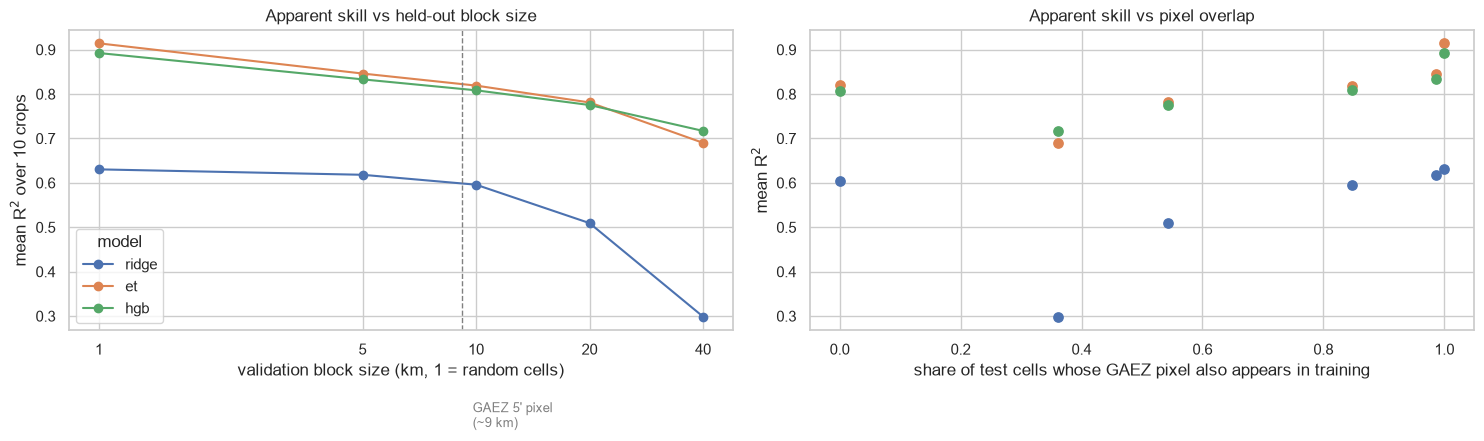

In [5]:
km = {"random": 1, **{f"block{k}": k for k in BLOCKS}}
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
for m in MODELS:
    ys = [res[(res.scheme == s) & (res.model == m)]["r2"].mean() for s in km]
    axes[0].plot(list(km.values()), ys, marker="o", label=m)
axes[0].axvline(9.2, color="grey", ls="--", lw=1)
axes[0].text(9.8, 0.05, "GAEZ 5' pixel\n(~9 km)", color="grey", fontsize=9)
axes[0].set(xscale="log", xlabel="validation block size (km, 1 = random cells)", ylabel="mean R$^2$ over 10 crops",
            title="Apparent skill vs held-out block size")
axes[0].set_xticks(list(km.values()), [str(v) for v in km.values()])
axes[0].legend(title="model")

for m in MODELS:
    sub = table[m]
    axes[1].scatter(table["pixel_overlap"], sub, label=m, s=45)
axes[1].set(xlabel="share of test cells whose GAEZ pixel also appears in training", ylabel="mean R$^2$",
            title="Apparent skill vs pixel overlap")
plt.tight_layout()
E.save_fig(fig, "m02_blocksize")
plt.show()